# Data exploration and design choices

This notebook justifies the choices behind `python main.py`. Each section asks one question, shows the evidence, and ends with the decision and the file where it is applied. The reasoning cites its sources in brackets; the full list is in `README.md`, section References, and "course" refers to the sessions of the Applied ML course (Sebag, 2026).

It only uses the training and validation sets. The test set is kept for the final scores of `main.py`, so no choice is made with it.

Part 1 only needs the data. Part 2 uses the models trained by `python main.py` and its Optuna run log, so run `python main.py` first. The whole notebook runs in about 3 minutes.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import calibration, eda, evaluation, fairness, imbalance, tuning
from src.config import TABLES, load_config
from src.data import TARGET, age_group, features_and_target, load_data, load_raw, split_data
from src.features import FeatureEngineer
from src.models import MODEL_NAMES, build_pipeline
from src.utils import load_json, load_model

pd.set_option("display.precision", 3)
config = load_config()

## Part 1. The data

The data is split before we look at it: 60% train, 20% validation and 20% test, stratified on the target. Part 1 uses the training set only, so nothing we learn here comes from the validation or test sets.

In [2]:
splits = split_data(load_data(config), config)
train = splits["train"]
numeric, categorical = eda.column_types(train)
print(f"{len(train):,} training rows, {train.shape[1] - 1} features")
train.head()

27,126 training rows, 15 features


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,subscribed
10333,43.0,services,married,secondary,no,2478.0,yes,no,unknown,12.0,jun,1.0,-1.0,0.0,unknown,0
9723,40.0,blue-collar,married,primary,no,676.0,no,no,unknown,9.0,jun,1.0,-1.0,0.0,unknown,0
22764,39.0,technician,married,secondary,no,3825.0,no,yes,cellular,25.0,aug,6.0,-1.0,0.0,unknown,0
23223,42.0,technician,divorced,secondary,no,324.0,yes,no,cellular,27.0,aug,2.0,-1.0,0.0,unknown,0
5594,31.0,blue-collar,married,secondary,no,631.0,yes,no,unknown,23.0,may,4.0,-1.0,0.0,unknown,0


### 1.1 Which columns can the model use?

The model must decide whom to call, so it can only use what is known before the call. `duration` is the length of the call.

In [3]:
duration = load_raw(config).loc[train.index, "duration"]
print(f"ROC-AUC of duration alone: {roc_auc_score(train[TARGET], duration):.3f}")

ROC-AUC of duration alone: 0.810


On its own, `duration` gives a ROC-AUC of 0.81, about as much as our best model with all the other features. But it is only known when the call is over, so using it would be target leakage (Kaufman et al., 2012; course, session 2). The authors of the data give the same warning: duration "should be discarded if the intention is to have a realistic predictive model" (Moro, Rita & Cortez, 2014, file `bank-additional-names.txt` of the UCI archive). All the other columns are known before the call.

**Decision:** `duration` is removed when the data is loaded (`load_data` in `src/data.py`).

### 1.2 Is the target balanced?

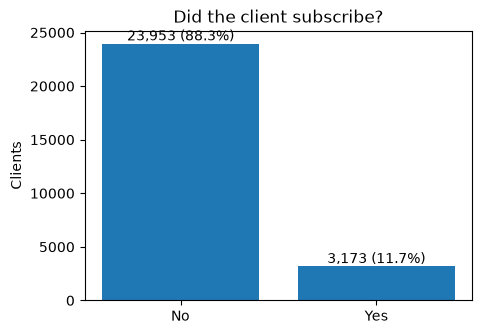

In [4]:
eda.plot_target(train);

Only 11.7% of the calls lead to a subscription. Always answering "no" gives 88.3% accuracy, so accuracy says nothing. ROC-AUC does not depend on the class balance either. Average precision focuses on the subscribers, the clients we want to find, and a model with no skill gets the subscription rate (0.117). On imbalanced data, the precision-recall curve is more informative than the ROC curve (Saito & Rehmsmeier, 2015; Davis & Goadrich, 2006; course, session 9).

**Decision:** average precision is the main metric, with ROC-AUC and the Brier score (Brier, 1950) next to it. Every split is stratified on the target (`src/data.py`). The decision threshold is not 0.5: it is chosen on the validation set (section 2.7).

### 1.3 Are there missing values or duplicates?

In [5]:
print(f"Duplicated rows: {train.duplicated().sum()}")
eda.overview(train)

Duplicated rows: 6


,dtype,missing,unknown,unique_values,example
column,,,,,
age,float64,0,0,76,43.0
job,str,0,179,12,services
marital,str,0,0,3,married
education,str,0,1100,4,secondary
default,str,0,0,2,no
balance,float64,0,0,5896,2478.0
housing,str,0,0,2,yes
loan,str,0,0,2,no
contact,str,0,7790,3,unknown


- There are no missing values (NaN). Four columns use the category `unknown` instead: `job`, `education`, `contact` (29% of the rows) and `poutcome` (82%). The fact that a value is missing can carry information (Little & Rubin, 2019), and it does here: only 4.3% of the clients with `contact = unknown` subscribe, against about 14% for the other contact types (section 1.7).
- `poutcome = unknown` and `pdays = -1` describe almost the same clients: the ones who were never contacted before.
- There are 6 duplicated rows out of 27,126 (0.02%). The data has no client id, so two different clients can have the same values.

**Decision:** no imputation, and `unknown` is one-hot encoded like any other category (`src/features.py`). The duplicates are kept: they are too few to matter.

### 1.4 Do the numeric features need cleaning?

In [6]:
eda.numeric_summary(train, numeric)

,count,mean,std,min,25%,50%,75%,max,outliers_iqr,skew
column,,,,,,,,,,
age,27126.0,40.894,10.633,18.0,33.0,39.0,48.00,95.0,304,0.708
balance,27126.0,1368.133,3087.754,-6847.0,73.0,454.0,1425.75,81204.0,2827,8.095
day,27126.0,15.801,8.323,1.0,8.0,16.0,21.00,31.0,0,0.093
campaign,27126.0,2.757,3.100,1.0,1.0,2.0,3.00,63.0,1838,4.944
pdays,27126.0,40.067,100.398,-1.0,-1.0,-1.0,-1.00,871.0,4891,2.617
previous,27126.0,0.576,1.966,0.0,0.0,0.0,0.00,58.0,4891,8.136


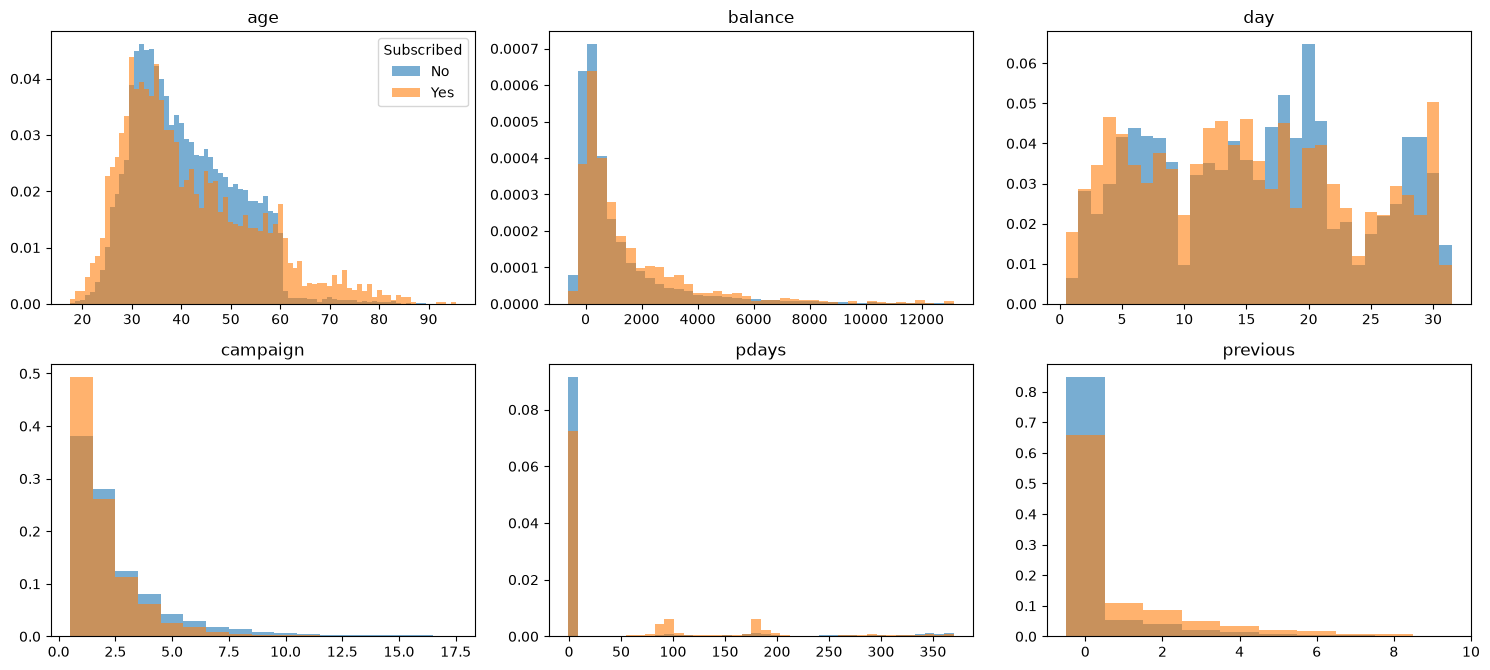

In [7]:
eda.plot_numeric(train, numeric);

- `balance`, `campaign` and `previous` are very skewed (skew above 4), with a few very large values, such as a balance of 81,204 or 63 calls in one campaign. These values are possible, not errors.
- The IQR rule (Tukey, 1977) flags 4,891 values of `pdays` and `previous`. These are simply all the clients who were contacted before: more than 75% of the values are -1 or 0, so any other value looks extreme.
- `pdays = -1` is a code for "never contacted", not a number of days (section 1.6).

**Decision:** no value is removed or clipped. Tree models only use the order of the values, so they are not sensitive to skew (Hastie et al., 2009, section 10.7). The logistic regression gets standardized features, because its L2 penalty treats all coefficients the same way (course, session 3; Hastie et al., 2009, section 3.4.1; `build_preprocessor` in `src/features.py`).

### 1.5 Are some features redundant?

Spearman correlation (Spearman, 1904), because several features are very skewed.

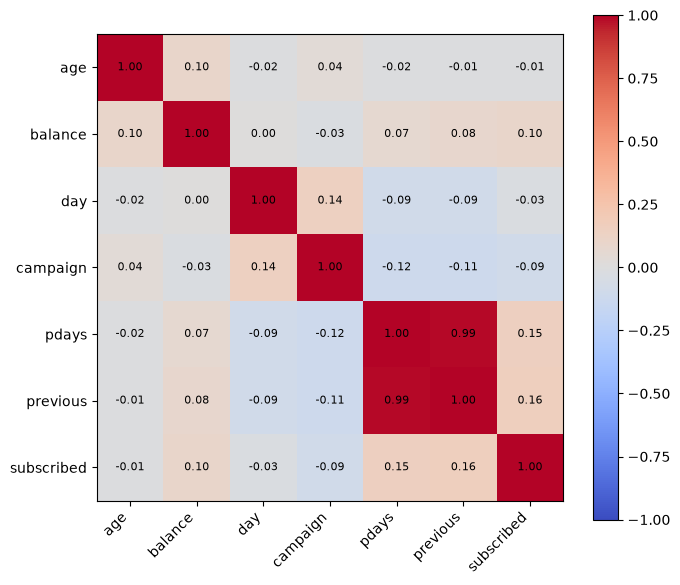

In [8]:
eda.plot_correlation(train, numeric);

`pdays` and `previous` have a correlation of 0.99, because both are -1 or 0 for the 82% of clients never contacted before. For the other clients they say different things: the number of days since the last contact and the number of contacts. No numeric feature is strongly correlated with the target (at most 0.16, for `previous`), but correlation only measures links that always go in the same direction: age has a correlation of -0.01, yet it matters a lot (section 1.8).

**Decision:** all numeric features are kept. Correlated features do not hurt the trees, and the L2 penalty of the logistic regression shares the weight between them (course, session 3).

### 1.6 Which features can we add?

In [9]:
engineered = FeatureEngineer().transform(train)
eda.subscription_rate_table(engineered, ["housing", "loan", "has_loan"])

count  share  subscription_rate
column   category                                 
housing  no        11976  0.441              0.167
         yes       15150  0.559              0.078
loan     no        22723  0.838              0.126
         yes        4403  0.162              0.070
has_loan 0         10264  0.378              0.182
         1         16862  0.622              0.078

In [10]:
contacts = engineered["previous"].clip(upper=5).rename("previous (5 = 5 or more)")
engineered.groupby(contacts)[TARGET].agg(clients="size", subscription_rate="mean")

,clients,subscription_rate
previous (5 = 5 or more),,
0.0,22235,0.093
1.0,1641,0.208
2.0,1251,0.219
3.0,658,0.243
4.0,426,0.249
5.0,915,0.256


In [11]:
engineered["campaign + previous"] = engineered["campaign"] + engineered["previous"]
engineered[["campaign", "previous", "campaign + previous"]].corrwith(
    engineered[TARGET], method="spearman"
)

campaign              -0.088
previous               0.164
campaign + previous    0.012
dtype: float64

- **`has_loan`** (housing loan or personal loan): 7.8% of the clients with a loan subscribe, against 18.2% of the clients without any loan. A client with a loan has less money to save.
- **`contacted_before`** (`previous > 0`): the rate jumps from 9.3% for the clients never contacted to 21-26% for the others, whatever the number of contacts. The feature states this jump directly, instead of hiding it in the code `pdays = -1`.
- **Rejected:** `campaign + previous`, the total number of contacts. Its two parts go in opposite directions (more calls in this campaign: fewer subscriptions; contacts in a previous campaign: more subscriptions), so the sum has almost no link with the target (0.01).

**Decision:** `FeatureEngineer` adds `has_loan` and `contacted_before` inside the pipeline (`src/features.py`). It learns nothing from the data, so it cannot leak (course, session 6; scikit-learn, "Common pitfalls"). Section 2.4 measures whether the two features help the models.

### 1.7 Which categories matter?

Subscription rate of each category, with its number of clients. The dashed line is the overall rate.

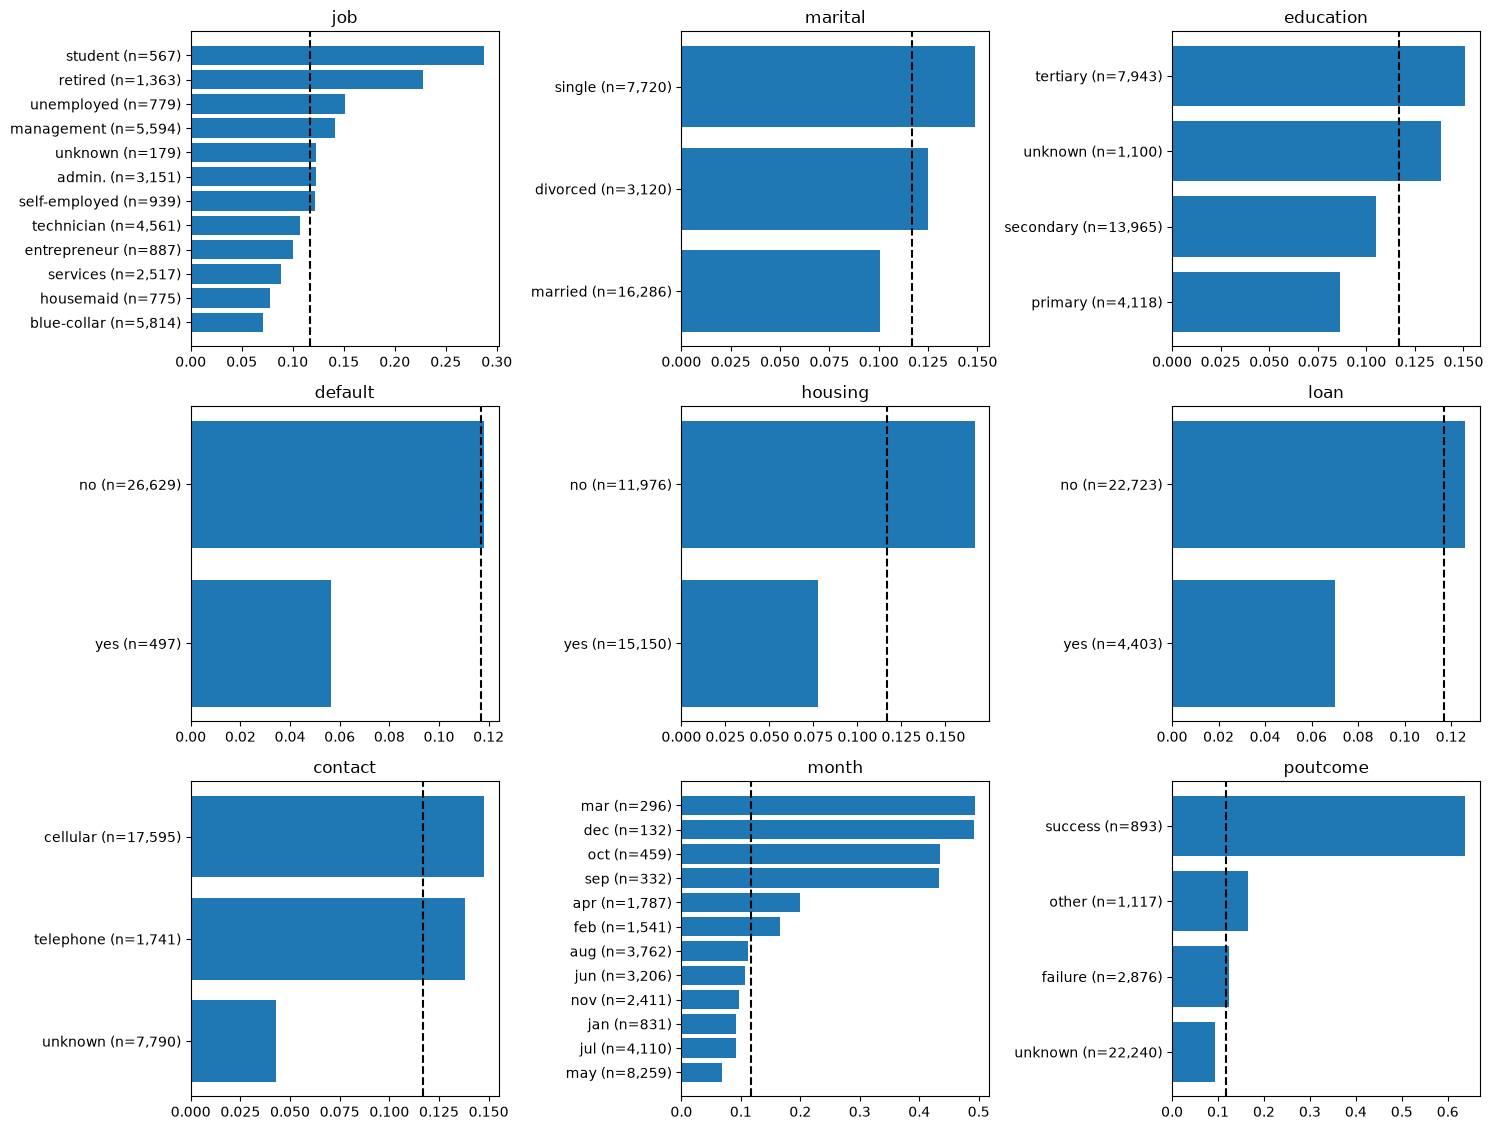

In [12]:
rates = eda.subscription_rate_table(train, categorical)
eda.plot_subscription_rate(rates, train[TARGET].mean());

- `poutcome = success`: 64% of the clients who said yes in the previous campaign say yes again. It is the strongest single signal.
- Students (29%) and retired clients (23%) subscribe much more than blue-collar workers (7%).
- March, September, October and December have rates above 40%, but they are small months (132 to 459 calls). May has 30% of the calls and the lowest rate (6.8%).
- The smallest category still has 132 clients.

**Decision:** all categorical columns are kept and one-hot encoded (course, session 6), without grouping rare categories. A category never seen in training (for example in an API request) is encoded as zeros (`handle_unknown="ignore"` in `src/features.py`).

### 1.8 Which age groups for the fairness audit?

Age is the sensitive attribute of this dataset, and a protected ground of non-discrimination in EU law (Charter of Fundamental Rights of the European Union, article 21).

In [13]:
age_bins = pd.cut(train["age"], bins=[17, 24, 29, 34, 39, 44, 49, 54, 59, 64, 100])
train.groupby(age_bins, observed=True)[TARGET].agg(clients="size", subscription_rate="mean")

,clients,subscription_rate
age,,
"(17, 24]",476,0.250
"(24, 29]",2719,0.160
"(29, 34]",5897,0.106
"(34, 39]",4957,0.108
"(39, 44]",3751,0.087
"(44, 49]",3275,0.099
"(49, 54]",2643,0.086
"(54, 59]",2325,0.095
"(59, 64]",588,0.272


The rate is high before 30 (16-25%), flat around 9-11% from 30 to 59, and high again from 60 (27-40%). This U shape also means that a linear model cannot use age well.

**Decision:** three groups that follow these breaks: 18-29, 30-59 and 60+ (`config.yaml`). The 60+ group is small (4% of the clients), so its rates are reported with 95% Wilson intervals, which stay reliable for small groups (Wilson, 1927; Brown, Cai & DasGupta, 2001; `src/fairness.py`).

### 1.9 Can we split the data at random?

The rows are in time order (May 2008 to November 2010), but there is no year column. We cut the training rows, in their original order, into 10 blocks of the same size.

,block,rows,subscription_rate,contact_unknown_share
0,1,2713,0.031,1.000e+00
1,2,2713,0.042,1.000e+00
2,3,2713,0.050,7.962e-01
3,4,2713,0.063,5.160e-03
4,5,2713,0.067,1.843e-03
5,6,2713,0.059,1.511e-02
6,7,2712,0.103,3.687e-04
7,8,2712,0.135,0.000e+00
8,9,2712,0.153,0.000e+00
9,10,2712,0.467,5.273e-02


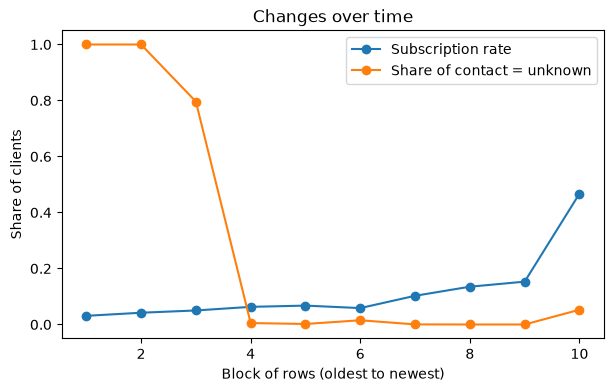

In [14]:
drift = eda.time_drift_table(train)
eda.plot_time_drift(drift)
drift

- The subscription rate rises from 3% in the oldest block to 47% in the newest one: the data changes over time, a dataset shift (Moreno-Torres et al., 2012).
- `contact = unknown` covers all the calls of the two oldest blocks and almost none after: the contact type was not recorded at the start. So `contact`, like `month`, partly tells the model **when** the call happened.

**Decision:** we keep a random stratified split, so that the model comparison and the threshold are not driven by the change of rate between periods. We report its scores as what they are: same-period scores, optimistic for a future campaign. Time-ordered evaluation is the standard for data that changes over time (Bergmeir & Benítez, 2012), so section 2.10 measures how much the scores drop with a split in time, and section 2.5 tests whether `contact` and `month` should be removed.

### Summary of Part 1

| Finding | Decision | Code |
|---|---|---|
| `duration` is only known after the call | Removed | `src/data.py` |
| Only 11.7% of the calls lead to a subscription | Average precision as main metric, stratified split, threshold chosen on validation | `src/data.py`, `src/evaluation.py` |
| No NaN, `unknown` carries information | No imputation, `unknown` kept as a category | `src/features.py` |
| Skewed features with large but possible values | Kept as they are, standardized for the logistic regression only | `src/features.py` |
| Clients with a loan subscribe less | New feature `has_loan` | `src/features.py` |
| The rate jumps after a first contact | New feature `contacted_before` | `src/features.py` |
| `campaign + previous` has no link with the target | Rejected | – |
| U-shaped link between age and the target | Age groups 18-29, 30-59, 60+ | `config.yaml` |
| Rows in time order, rate from 3% to 47% | Random split, reported as same-period scores, plus a time split check | `src/evaluation.py` |

## Part 2. Modelling choices

Each model is one scikit-learn `Pipeline`: `FeatureEngineer`, preprocessing, then the model. Cross-validation therefore fits the preprocessing again in every fold, which prevents leakage (course, session 6). All cross-validations use the same 5 stratified folds of the training set.

### 2.1 Class weights or a decision threshold?

Default settings, with and without `class_weight="balanced"`. This takes about 30 seconds.

In [15]:
X_train, y_train = features_and_target(train)
imbalance.compare_class_weights(X_train, y_train, config)

,model,class_weight,average_precision,roc_auc,brier,precision_at_0.5,recall_at_0.5,average_precision_std
0,logistic_regression,none,0.399,0.761,0.087,0.630,0.165,0.013
1,logistic_regression,balanced,0.396,0.762,0.185,0.265,0.622,0.014
2,random_forest,none,0.410,0.774,0.086,0.596,0.208,0.009
3,random_forest,balanced,0.404,0.776,0.098,0.464,0.391,0.013
4,lightgbm,none,0.423,0.789,0.084,0.599,0.236,0.011
5,lightgbm,balanced,0.423,0.789,0.151,0.349,0.601,0.009


The weights do not change the average precision: the differences (at most 0.006) are smaller than the standard deviation across folds (about 0.01). But they make the Brier score much worse, for example 0.087 to 0.185 for the logistic regression, so the probabilities are no longer reliable. The weights only move the decisions (higher recall at 0.5), and a threshold does the same without damaging the probabilities. This agrees with van den Goorbergh et al. (2022): imbalance corrections such as oversampling, which class weights imitate, damage the probabilities without improving discrimination.

**Decision:** no class weights. The decision threshold is chosen on the validation set (section 2.7).

### 2.2 Which model families?

Before the tuning, one or two models of each family are compared with their default settings. The rule was fixed before the results: each family is represented by its best model, a new model replaces the one we already use only if it is better by more than the standard deviation across folds, and the three best families are tuned. Fixing the rule first avoids choosing by chance among many close candidates (Cawley & Talbot, 2010). This takes about 30 seconds.

In [16]:
tuning.screen_models(X_train, y_train, config)

,family,model,average_precision,roc_auc,brier,average_precision_std
0,boosting,hist_gradient_boosting,0.430,0.792,0.083,0.012
1,boosting,lightgbm,0.423,0.789,0.084,0.011
2,bagging,random_forest,0.410,0.774,0.086,0.009
3,linear,logistic_regression,0.399,0.761,0.087,0.013
4,bagging,extra_trees,0.351,0.751,0.094,0.011
5,naive Bayes,naive_bayes,0.344,0.740,0.159,0.015
6,nearest neighbours,knn,0.258,0.682,0.101,0.004
7,single tree,decision_tree,0.170,0.605,0.171,0.005


- The three best families are boosting (0.430 and 0.423), bagging (0.410) and linear (0.399).
- HistGradientBoosting is ahead of LightGBM by 0.007, less than the standard deviation across folds (0.012), so LightGBM stays. Both use the same method: gradient boosting on histograms of the features (Ke et al., 2017; the scikit-learn documentation says HistGradientBoosting "is inspired by LightGBM").
- Extra trees (Geurts et al., 2006) are far behind the random forest (Breiman, 2001): 0.351 against 0.410.
- Naive Bayes (0.344) assumes independent features (Hand & Yu, 2001), while `pdays` and `previous` are almost the same variable. k-nearest neighbours (0.258) and a single decision tree (0.170) are far behind. Their default settings are weak (5 neighbours, a tree that grows until each leaf is pure), so tuning would improve them; we did not check whether it would close a gap of this size.
- An SVM was not tested: it gives no probabilities without an extra calibration step (Platt, 1999), and its fit time grows at least quadratically with the number of rows (scikit-learn, `SVC` documentation).
- Neural networks were not tested: on tabular data of this size, tree ensembles usually do at least as well (Grinsztajn et al., 2022).

**Decision:** the baseline, then one model of each of the three best families: logistic regression, random forest and LightGBM (`MODEL_NAMES` in `src/models.py`). They go from the simplest model to the most flexible, so the comparison shows what each step adds.

### 2.3 Is the Optuna search large enough?

Optuna (Akiba et al., 2019) with its TPE sampler (Bergstra et al., 2011; course, session 6) runs 30 trials per model. Each trial scores the whole pipeline in cross-validation, and the objective is the mean average precision. The run log of `python main.py` has one row per trial.

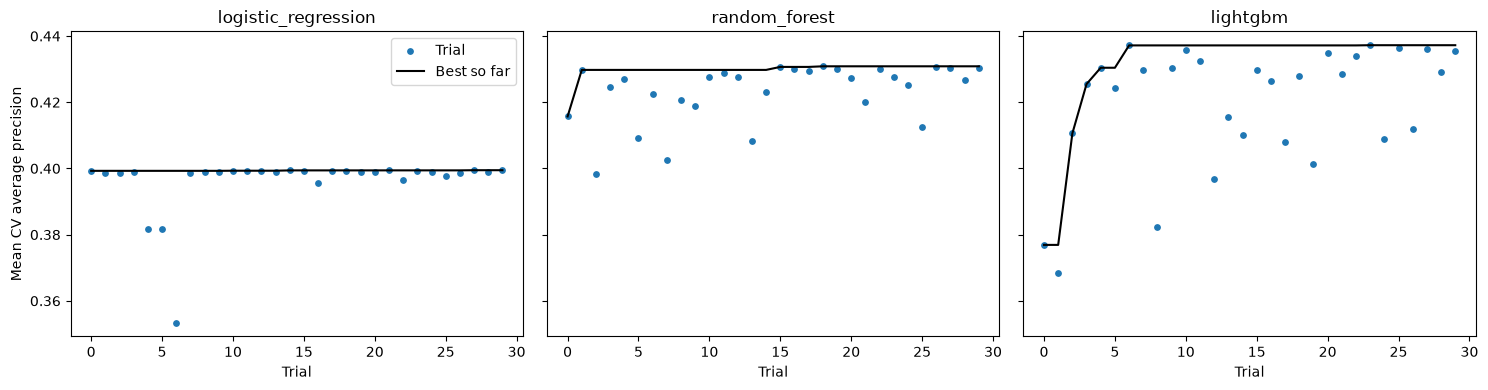

In [17]:
run_log = pd.read_csv(TABLES / "tuning_run_log.csv")
tuning.plot_history(run_log);

In [18]:
for name in MODEL_NAMES:
    trials = run_log[run_log["model"] == name]
    params = pd.DataFrame(trials["params"].map(json.loads).tolist())
    best = params[trials["is_best"].to_numpy()].iloc[0]
    ranges = pd.DataFrame({"lowest tried": params.min(), "best": best, "highest tried": params.max()})
    display(ranges.rename_axis(name))

,lowest tried,best,highest tried
logistic_regression,,,
C,0.002,0.228,56.698


,lowest tried,best,highest tried
random_forest,,,
max_depth,4.000,16.000,20.00
min_samples_leaf,1.000,3.000,40.00
max_features,0.069,0.242,0.68


,lowest tried,best,highest tried
lightgbm,,,
n_estimators,100.000,400.000,900.000
learning_rate,0.011,0.127,0.198
num_leaves,2.000,3.000,110.000
min_child_samples,16.000,50.000,183.000


- The best score stops improving early: every model is within 0.002 of its best score by trial 6, so 30 trials are enough.
- The best values are inside the ranges. LightGBM prefers very small trees: 3 leaves, next to the lower limit of 2, which is the smallest value LightGBM allows. The range cannot go lower.
- The best CV score is the best of 30 trials, so it is a little optimistic (Cawley & Talbot, 2010; course, session 6). This is why the models are compared again on the validation set, which the search never saw.

**Decision:** 30 trials per model and the search spaces of `suggest_params` (`src/models.py`). The number of trees of the random forest is fixed at 300 and not tuned, because more trees only lower the variance (Breiman, 2001; Probst & Boulesteix, 2018).

### 2.4 Do the new features help the models?

Best parameters of each model, with and without `FeatureEngineer`. This takes about 20 seconds.

In [19]:
best_params = load_json("tuning_best_params")
ablation = {}
for name in MODEL_NAMES:
    for version in ["with", "without"]:
        pipeline = build_pipeline(name, best_params[name], config["seed"])
        if version == "without":
            pipeline.set_params(features="passthrough")
        scores = tuning.cross_validated_scores(pipeline, X_train, y_train, config)
        ablation[name, version] = {
            "average_precision": scores["average_precision"].mean(),
            "average_precision_std": scores["average_precision"].std(),
            "roc_auc": scores["roc_auc"].mean(),
            "brier": scores["brier"].mean(),
        }
pd.DataFrame(ablation).T.rename_axis(["model", "new features"])

average_precision  average_precision_std  \
model               new features                                             
logistic_regression with                      0.399                  0.012   
                    without                   0.399                  0.012   
random_forest       with                      0.431                  0.005   
                    without                   0.431                  0.004   
lightgbm            with                      0.437                  0.011   
                    without                   0.439                  0.008   

                                  roc_auc  brier  
model               new features                  
logistic_regression with            0.762  0.087  
                    without         0.761  0.087  
random_forest       with            0.790  0.083  
                    without         0.790  0.083  
lightgbm            with            0.791  0.083  
                    without         0.792  0.083

Neither feature improves any model: the differences are smaller than 0.002 AP, far below the standard deviation across folds (0.004 to 0.012). The models already find the same information in the original columns: `housing` and `loan` for `has_loan`, and `poutcome = unknown` and `pdays = -1` for `contacted_before`. The signal seen in section 1.6 is real, but it is not new.

**Decision:** we keep the two features, because each one states a business fact in a single column that is easy to read in the SHAP analysis. They do not make the model better, and we do not claim that they do.

### 2.5 Should we keep `contact` and `month`?

Section 1.9 showed that both partly tell the model when the call happened. We score each model without them, in cross-validation (same period) and on the time split of section 2.10 (newer clients). The rule was fixed before the results: a column is removed if removing it costs less than the standard deviation across folds in cross-validation, and does not make the time split worse. This takes about a minute.

In [20]:
oldest, newest = evaluation.time_split(splits)
X_old, y_old = features_and_target(oldest)
X_new, y_new = features_and_target(newest)
rows = []
for name in MODEL_NAMES:
    for dropped in [[], ["contact"], ["month"]]:
        pipeline = build_pipeline(name, best_params[name], config["seed"])
        scores = tuning.cross_validated_scores(pipeline, X_train.drop(columns=dropped), y_train, config)
        pipeline.fit(X_old.drop(columns=dropped), y_old)
        proba = pipeline.predict_proba(X_new.drop(columns=dropped))[:, 1]
        rows.append({
            "model": name,
            "removed": ", ".join(dropped) or "nothing",
            "cv_average_precision": scores["average_precision"].mean(),
            "cv_average_precision_std": scores["average_precision"].std(),
            "time_split_roc_auc": roc_auc_score(y_new, proba),
        })
pd.DataFrame(rows).set_index(["model", "removed"])

cv_average_precision  cv_average_precision_std  \
model               removed                                                   
logistic_regression nothing                 0.399                     0.012   
                    contact                 0.383                     0.014   
                    month                   0.362                     0.008   
random_forest       nothing                 0.431                     0.005   
                    contact                 0.421                     0.008   
                    month                   0.390                     0.005   
lightgbm            nothing                 0.437                     0.011   
                    contact                 0.421                     0.011   
                    month                   0.393                     0.011   

                             time_split_roc_auc  
model               removed                      
logistic_regression nothing               0.737  
                    contact               0.741  
                    month                 0.707  
random_forest       nothing               0.719  
                    contact               0.732  
                    month                 0.686  
lightgbm            nothing               0.728  
                    contact               0.737  
                    month                 0.703

- Removing `contact` costs 0.010 to 0.017 AP in cross-validation, more than the standard deviation across folds. On the time split, it gives a slightly better ROC-AUC (+0.004 to +0.013). Within one period, `contact = unknown` helps because it tells the model that the call is an early one, with a low rate. For newer clients, this information is useless.
- Removing `month` costs about 0.04 AP in cross-validation, and it also lowers the ROC-AUC on the time split by about 0.03. So `month` is not only a sign of the period: it also carries signal for newer clients.

**Decision:** both columns are kept, as the rule says. `contact` stays a known weakness: it makes the same-period scores a little better, some predictions are explained by the period of the call, and a model for a new campaign should be checked without it.

### 2.6 Which model?

Each model is trained on the whole training set with its best parameters, and scored on the validation set. The dashed lines show a model with no skill.

In [21]:
models = {name: load_model(name) for name in ["baseline", *MODEL_NAMES]}
X_val, y_val = features_and_target(splits["validation"])
val_proba = {name: model.predict_proba(X_val)[:, 1] for name, model in models.items()}
thresholds = {name: evaluation.best_threshold(y_val, proba) for name, proba in val_proba.items()}
validation = evaluation.metrics_table(y_val, val_proba, thresholds)
validation

,average_precision,roc_auc,brier,threshold,precision,recall,f1,balanced_accuracy
model,,,,,,,,
baseline,0.117,0.500,0.103,1.000,0.000,0.000,0.000,0.500
logistic_regression,0.413,0.770,0.085,0.141,0.324,0.570,0.413,0.706
random_forest,0.470,0.803,0.080,0.128,0.358,0.644,0.460,0.745
lightgbm,0.464,0.808,0.080,0.135,0.380,0.629,0.474,0.746


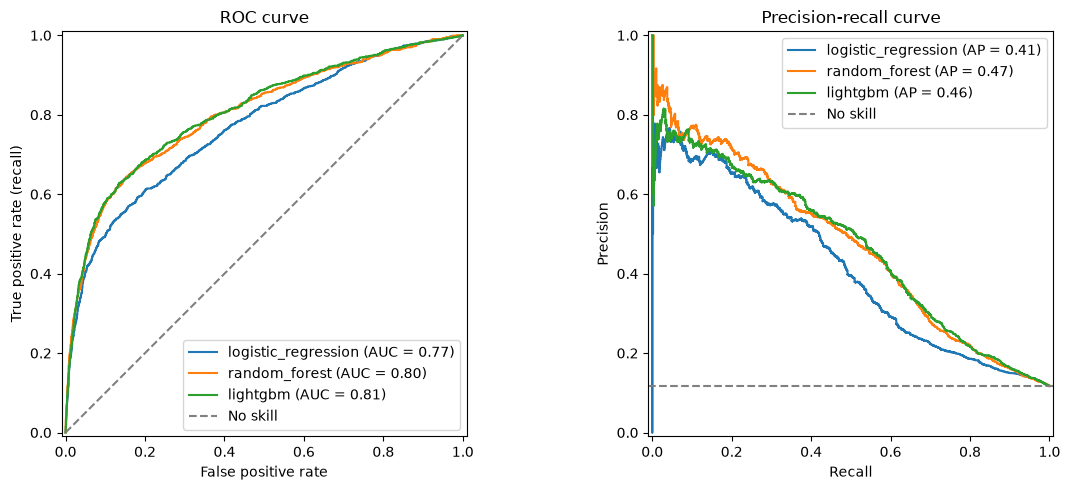

In [22]:
evaluation.plot_curves(y_val, {name: val_proba[name] for name in MODEL_NAMES});

In [23]:
final = validation.loc[MODEL_NAMES, "average_precision"].idxmax()
final

'random_forest'

Precision, recall and balanced accuracy in this table use a threshold chosen on these same rows, so they are a little optimistic. The test scores of `main.py` are not. What each model adds (validation average precision):

- **Baseline to logistic regression** (0.117 to 0.413): the features carry real signal.
- **Logistic regression to the tree models** (0.413 to about 0.47): trees capture non-linear effects and interactions, such as the U shape of age (section 1.8; course, sessions 4 and 5).
- **Random forest against LightGBM** (0.470 and 0.464): a tie. Cross-validation puts LightGBM first (0.437 against 0.431), the validation set puts the random forest first, and both gaps are about the size of the standard deviation across folds.

**Decision:** the rule, fixed before the experiments, is to keep the model with the best validation average precision: the random forest (`run_evaluate` in `main.py`). We do not change the rule after seeing the results, because that would bias the estimate (Cawley & Talbot, 2010). LightGBM would be an equally good choice.

### 2.7 Which decision threshold?

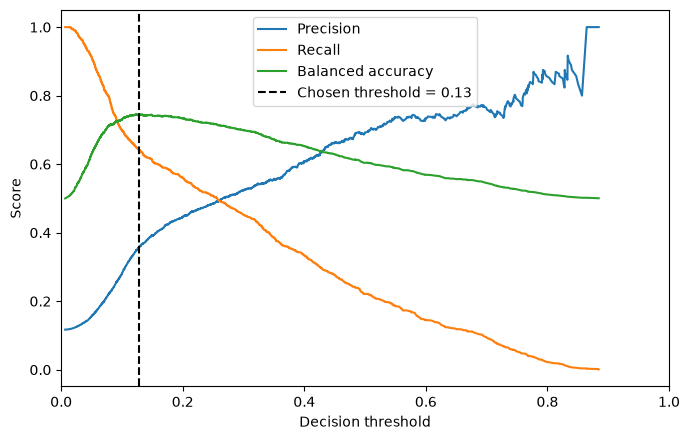

In [24]:
evaluation.plot_threshold(y_val, val_proba[final], thresholds[final]);

We choose the threshold with the best balanced accuracy on the validation set: 0.128. The best balanced accuracy is the maximum of Youden's index (Youden, 1950), and it minimises the expected cost when one missed subscriber is as costly as about 7.5 useless calls, the ratio of non-subscribers to subscribers (Elkan, 2001). We have no real costs from the bank, so this is an assumption that the bank should check. The probabilities are close to the real rates (section 2.8), so the threshold is close to the subscription rate (0.117).

**Decision:** threshold 0.128, saved with the model (`best_threshold` in `src/evaluation.py`).

### 2.8 Can we trust the probabilities as they are?

{'brier': 0.0799475061163712, 'ece': np.float64(0.011257363394598064), 'mean_predicted': np.float64(0.11801050066110133), 'observed_rate': np.float64(0.11700951117009512)}


,count,mean_predicted,observed_rate,gap
bin,,,,
"(-0.001, 0.1]",6406,0.054,0.050,-0.004
"(0.1, 0.2]",1307,0.131,0.112,-0.020
"(0.2, 0.3]",414,0.245,0.275,0.030
"(0.3, 0.4]",336,0.348,0.378,0.030
"(0.4, 0.5]",242,0.445,0.488,0.042
"(0.5, 0.6]",129,0.550,0.628,0.078
"(0.6, 0.7]",78,0.652,0.692,0.041
"(0.7, 0.8]",103,0.746,0.738,-0.008
"(0.8, 0.9]",27,0.835,0.852,0.017


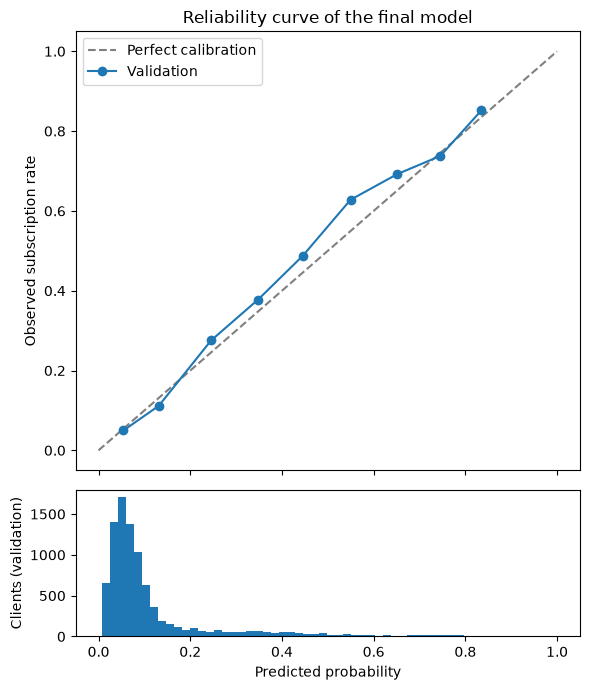

In [25]:
calibration_val = calibration.calibration_table(y_val, val_proba[final])
print(calibration.summarize(y_val, val_proba[final], calibration_val))
calibration.plot_reliability({"validation": calibration_val}, val_proba[final], "validation")
calibration_val

The reliability curve (DeGroot & Fienberg, 1983; course, session 9) compares the predicted probabilities with the observed rates.

- The expected calibration error (ECE; Naeini et al., 2015; Guo et al., 2017) is 0.011, and the mean prediction (11.8%) matches the observed rate (11.7%). With equal-width bins, the ECE is dominated by the first bin, which holds 70% of the clients, so we also read the bins one by one (Nixon et al., 2019).
- Below 0.2, where most clients are, the gaps are at most 2 points.
- Between 0.2 and 0.7, the model is slightly under-confident: the observed rate is 3 to 8 points above the prediction. These bins are small (78 to 414 clients). Averaging models such as random forests are known to have difficulty predicting probabilities near 0 and 1 (scikit-learn, "Probability calibration", citing Niculescu-Mizil & Caruana, 2005).
- Above 0.7, the gaps are small on validation (130 clients).

**Decision:** no recalibration. We trust the probabilities as they are to rank the clients and to apply the threshold, which falls in a bin with a small gap. We would not use them as exact probabilities above 0.2, nor for a new campaign (section 2.10).

### 2.9 Which fairness definition and which mitigation?

Rates of each age group on the validation set, with the single threshold.

In [26]:
groups_val = age_group(splits["validation"], config)
single = (val_proba[final] >= thresholds[final]).astype(int)
fairness.group_table(y_val, single, groups_val)

,clients,subscribers,subscription_rate,precision,selection_rate,selection_rate_low,selection_rate_high,true_positive_rate,true_positive_rate_low,true_positive_rate_high,false_positive_rate,false_positive_rate_low,false_positive_rate_high
group,,,,,,,,,,,,,
18-29,1075,196,0.182,0.345,0.407,0.378,0.437,0.77,0.707,0.824,0.327,0.296,0.358
30-59,7603,734,0.097,0.347,0.156,0.148,0.164,0.56,0.524,0.595,0.113,0.105,0.120
60+,364,128,0.352,0.423,0.772,0.726,0.812,0.93,0.872,0.963,0.686,0.625,0.742


The subscription rate is very different between age groups: 18% for 18-29, 10% for 30-59 and 35% for 60+.

- **Demographic parity** (the same share of calls in every group; Dwork et al., 2012; Barocas, Hardt & Narayanan, 2023) would ignore these real differences: the bank would call fewer clients aged 60+, while one in three of them subscribes.
- **Equal opportunity** (the same recall in every group; Hardt, Price & Srebro, 2016) asks that every client who would subscribe has the same chance to be called, whatever their age. This matches the goal of the campaign: finding the subscribers.

With a single threshold, the model finds 93% of the subscribers aged 60+ but only 56% of those aged 30-59, and the two intervals do not overlap.

**Decision:** equal opportunity, with a post-processing mitigation (Hardt, Price & Srebro, 2016): one threshold per age group, chosen on the validation set so that every group reaches the overall recall of the single threshold (64%). The model is not trained again, and the rule is deterministic: two identical clients always get the same decision. We rejected fairlearn's `ThresholdOptimizer` for this reason, because its predictions are randomized (fairlearn documentation; `equal_opportunity_thresholds` in `src/fairness.py`).

In [27]:
fairness.equal_opportunity_thresholds(y_val, val_proba[final], groups_val, thresholds[final])

{'18-29': 0.21878258040949944,
 '30-59': 0.09204446147508806,
 '60+': 0.326280250924248}

The 30-59 group gets a lower threshold (0.092), and the two other groups get higher ones (0.219 and 0.326). `main.py` measures the effect on the test set.

### 2.10 How optimistic is the random split?

The final model type is trained again on the oldest rows of train + validation and scored on the newest ones, with the same sizes as train and validation.

In [28]:
params = load_json("tuning_best_params")[final]
evaluation.time_split_check(splits, models[final], final, params, config["seed"])

,fit_subscription_rate,eval_subscription_rate,mean_predicted,roc_auc,average_precision,ap_lift
split,,,,,,
random,0.117,0.117,0.118,0.803,0.470,4.021
time,0.064,0.275,0.145,0.719,0.448,1.632


AP depends on the subscription rate (Saito & Rehmsmeier, 2015), so we compare ROC-AUC and `ap_lift` (AP divided by the subscription rate). With the time split, ROC-AUC drops from 0.803 to 0.719 and `ap_lift` from 4.0 to 1.6. The model also predicts 14.5% on average, while 27.5% of the newer clients subscribed.

This is an order of magnitude, not an exact measure. The drop mixes two kinds of dataset shift (Moreno-Torres et al., 2012): the change of the subscription rate and a change of the features (38% of the older rows have `contact = unknown`, against 2% of the newer ones). The hyperparameters also come from a random cross-validation.

**Decision:** the scores of the random split are reported as same-period scores, and this drop is a limitation of the project. A real deployment would need a time-based validation and regular recalibration.

With these choices fixed, `python main.py` reports the final scores on the test set, the calibration on the test set, the SHAP explanations and the fairness before and after mitigation. The results are in `outputs/`.